# 06 · The Oracle — Fine-tuning BERT (`bert-base-uncased`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/06_bert.ipynb)

Steps 2–4 built the sentence representation from the bottom up: sparse word counts, static GloVe vectors, and a BiLSTM that composes the static vectors in order. This notebook uses a **pre-trained Transformer encoder**. BERT (Devlin et al., 2019) represents every token by **self-attention** over the whole sentence, so the vector of *feel* in *i feel happy* differs from the vector of *feel* in *i do not feel happy*. For classification, the output vector at the `[CLS]` position is passed to a linear classifier.

| Model id | BERT parameters | Classifier input | Trained parameters |
|---|---|---|---|
| `bert_finetuned` | **updated** (full fine-tuning) | `[CLS]` → pooler | all 109.5M |
| `bert_frozen` | **fixed** (pre-trained values) | `[CLS]` → pooler | the linear layer only (4,614) |
| `bert_frozen_mean` | fixed | mean of the last-layer token vectors | a linear layer (4,614); diagnostic |
| `bert` | role name: the variant selected on validation | | |

Questions answered here:

1. How does WordPiece tokenisation change the vocabulary problem of Steps 2–4? (§3)
2. Which learning rate and checkpoint does validation macro-F1 select, and how stable is fine-tuning across random seeds? (§5)
3. How much does updating the encoder add over a frozen pre-trained encoder with the same classification layer? (§6–7)
4. Is BERT significantly better than the best classical model and the BiLSTM? (§7) Where does it gain? (§8)
5. What do the self-attention weights look at? (§11)

**How to run.** Training needs a GPU: open the notebook in Colab with the badge above and choose *Runtime → Change runtime type → T4 GPU*. The whole notebook takes roughly 30–40 minutes on a T4. Training runs are saved to Google Drive (§0), so after a disconnection a re-run continues from the finished runs. The fine-tuned model is saved to `models/bert/` and backed up on the Hugging Face Hub (§14); §15 downloads the result files for the GitHub repository. Inference on the Mac uses `src/bert_infer.py`.

## 0. Setup

In [1]:
# Environment setup: runs on Google Colab (GPU, needed for training) and locally.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides torch, transformers and scikit-learn; only the repository is cloned (or updated).
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=False)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))

# Training runs (histories, logits, checkpoints) are kept outside the repository. On Colab they go to
# Google Drive, so that a disconnected runtime resumes from the runs that have already finished.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    RUN_DIR = Path("/content/drive/MyDrive/emotion-mirror-cbs4702/bert_runs")
else:
    RUN_DIR = ROOT / "models" / "bert_runs"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB} | training runs: {RUN_DIR}")

Mounted at /content/drive
Project root: /content/emotion-mirror-cbs4702 | running on Colab: True | training runs: /content/drive/MyDrive/emotion-mirror-cbs4702/bert_runs


In [2]:
import copy
import json
import math
import shutil
import time
from collections import Counter
from dataclasses import asdict, dataclass, replace
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import Markdown, display
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score, log_loss
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    BertForSequenceClassification,
    BertModel,
    BertTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

from src.bert_infer import (
    MAX_LENGTH,
    BertEmotionClassifier,
    get_device,
    predict_logits,
    save_model,
    softmax_with_temperature,
)
from src.config import (
    BERT_BASE_MODEL,
    BERT_DIR,
    BERT_HUB_REPO,
    FIG_DIR,
    ID2LABEL,
    LABEL2ID,
    LABELS,
    METRICS_DIR,
    MODELS_DIR,
    NUM_LABELS,
    PRED_DIR,
    SEED,
    ensure_dirs,
    set_seed,
)
from src.data import load_splits, tokenize
from src.evaluate import (
    evaluate,
    mcnemar_test,
    paired_bootstrap,
    plot_confusion_matrix,
    plot_per_class_f1,
    summary_table,
)
from src.slices import has_negation, training_vocabulary, unseen_word_mask

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
transformers.logging.set_verbosity_error()  # keep the training output readable; the loading report is shown in §2.2
transformers.utils.logging.disable_progress_bar()  # no progress bar for every checkpoint load and save

MODEL_NAME = BERT_BASE_MODEL  # "bert-base-uncased": 12 layers, 12 heads, hidden size 768, WordPiece vocabulary of 30,522
LABEL_IDS = list(range(NUM_LABELS))

DEVICE = get_device()
USE_AMP = DEVICE.type == "cuda"  # fp16 mixed precision on the T4 tensor cores; full fp32 elsewhere
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else DEVICE.type
print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | device: {GPU_NAME} | mixed precision: {USE_AMP}")
if DEVICE.type != "cuda":
    print("WARNING: no CUDA GPU. Full fine-tuning would take hours; on Colab choose Runtime -> Change runtime type -> T4 GPU.")


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary selection metric: unweighted mean of the six per-class F1 scores.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled test sets (as in 05).
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


def holm(p_values):
    # Holm step-down adjustment of a list of p-values (controls the family-wise error rate).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted

PyTorch 2.14.1+cu130 | transformers 5.22.1 | device: Tesla T4 | mixed precision: True


## 1. Data and reference models

The reference models are the best sparse model (`improved_lr`, Step 3) and the selected BiLSTM (`bilstm`, fine-tuned GloVe, Step 4). Their saved test predictions are used for the paired tests; the check below confirms that the saved predictions are aligned with the test texts row by row.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]
X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()
tokens = {name: [tokenize(t) for t in X] for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]}
train_vocab = training_vocabulary(X_train)  # shared definition from src/slices.py (Step 3)

REFERENCE = {
    "tfidf_lr": "TF-IDF + LR",
    "improved_lr": "Improved sparse LR",
    "glove_lr": "GloVe + LR",
    "bilstm_frozen": "BiLSTM (frozen GloVe)",
    "bilstm_finetuned": "BiLSTM (fine-tuned GloVe)",
    "bilstm": "BiLSTM [selected]",
}
reference_preds = {"validation": {}, "test": {}}
for m in REFERENCE:
    for split, X in [("validation", X_val), ("test", X_test)]:
        df = pd.read_csv(PRED_DIR / f"{m}__{split}.csv")
        assert df["text"].tolist() == X, f"{m}__{split}.csv is not aligned with the {split} split"
        reference_preds[split][m] = df["pred"].to_numpy()

DISPLAY_NAMES = {
    **REFERENCE,
    "bert_frozen": "BERT frozen ([CLS] pooler) + linear",
    "bert_frozen_mean": "BERT frozen (token mean) + linear",
    "bert_finetuned": "BERT fine-tuned",
}
print(f"train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,} | reference models: {', '.join(REFERENCE)}")

train 16,000 | validation 2,000 | test 2,000 | reference models: tfidf_lr, improved_lr, glove_lr, bilstm_frozen, bilstm_finetuned, bilstm


## 2. BERT

### 2.1 Self-attention and contextual vectors

BERT-base is a stack of $L = 12$ Transformer **encoder** layers with hidden size $d_{\text{model}} = 768$. Each layer applies multi-head self-attention followed by a position-wise feed-forward network, each wrapped in a residual connection and layer normalisation. For the token vectors $X \in \mathbb{R}^{n \times 768}$ of a sentence, one attention head computes

$$
Q = XW^Q,\quad K = XW^K,\quad V = XW^V,\qquad
\operatorname{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V,
$$

with $d_k = 768 / 12 = 64$. Row $i$ of the softmax matrix contains the weights $\alpha_{ij}$ with which token $i$ reads every token $j$ of the sentence; 12 heads run in parallel and their outputs are concatenated. Unlike the BiLSTM, every token reaches every other token in one step (path length 1 instead of up to $n$), and all positions are computed in parallel. Word order enters only through the learned **position embeddings** added to the input.

The input of BERT is `[CLS] w1 … wn [SEP]`; each input vector is the sum of a WordPiece embedding, a segment embedding (sentence A / B) and a position embedding. BERT was **pre-trained** on BooksCorpus and English Wikipedia (3.3B words) with two self-supervised tasks: masked language modelling (predict 15% masked WordPieces from both sides) and next-sentence prediction, which trains the `[CLS]` vector to summarise a sentence pair.

The cell below goes through the input pipeline step by step: mark the sentence with `[CLS]` and `[SEP]`, split it into WordPieces, map the pieces to vocabulary ids, and run the pre-trained encoder.

In [4]:
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
encoder = BertModel.from_pretrained(MODEL_NAME, output_hidden_states=True)
encoder.eval()

text = "i feel so lonely without you"
marked_text = "[CLS] " + text + " [SEP]"
tokenized_text = tokenizer.tokenize(marked_text)
indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text)
segments_ids = [0] * len(tokenized_text)  # a single sentence: every token belongs to segment A

tokens_tensor = torch.tensor([indexed_tokens])
segments_tensors = torch.tensor([segments_ids])
with torch.no_grad():
    outputs = encoder(tokens_tensor, token_type_ids=segments_tensors)

last_hidden_states = outputs.last_hidden_state  # (batch, sequence length, 768): one contextual vector per token
cls_vector = last_hidden_states[:, 0, :]  # the [CLS] vector, used for classification (§2.2)
display(pd.DataFrame({"WordPiece": tokenized_text, "id": indexed_tokens}).T)
print(f"last_hidden_state {tuple(last_hidden_states.shape)} | [CLS] vector {tuple(cls_vector.shape)} | "
      f"pooler_output {tuple(outputs.pooler_output.shape)} | hidden states: {len(outputs.hidden_states)} "
      f"(embedding layer + {encoder.config.num_hidden_layers} encoder layers)")

# The same input in one call: tokenizer(...) adds [CLS] and [SEP] and returns input_ids, token_type_ids and attention_mask.
inputs = tokenizer(text, return_tensors="pt")
assert inputs["input_ids"][0].tolist() == indexed_tokens
print("tokenizer(text) keys:", list(inputs.keys()))

,0,1,2,3,4,5,6,7
WordPiece,[CLS],i,feel,so,lonely,without,you,[SEP]
id,101,1045,2514,2061,9479,2302,2017,102


last_hidden_state (1, 8, 768) | [CLS] vector (1, 768) | pooler_output (1, 768) | hidden states: 13 (embedding layer + 12 encoder layers)
tokenizer(text) keys: ['input_ids', 'token_type_ids', 'attention_mask']


**Contextual vs static vectors.** A GloVe vector (Step 4) is the same for a word in every sentence. In BERT, the vector of *feel* at layer $l$ depends on the whole sentence. The figure compares the vector of *feel* in *i feel happy* with its vector in three other sentences, layer by layer. Layer 0 is the input embedding (WordPiece + position + segment), so it is identical whenever *feel* stands at the same position and differs only through the position embedding otherwise (*i do not feel happy*). From layer 1 on, every vector mixes in information from the whole sentence through self-attention, and the vectors of the same word type diverge with depth (Ethayarajh, 2019).

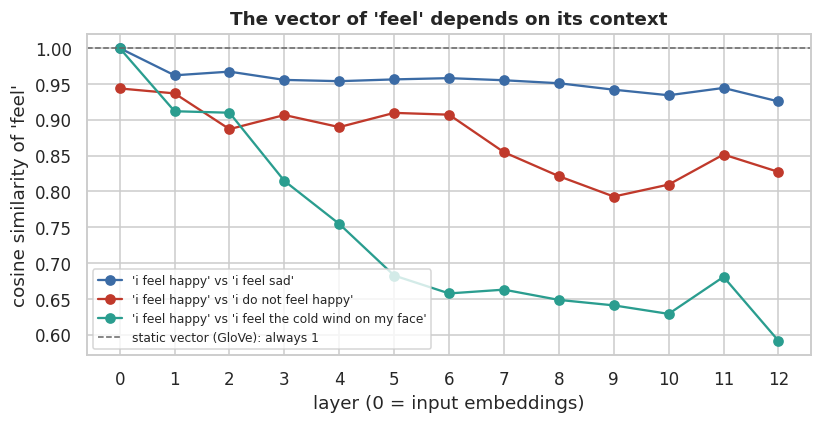

,'i feel happy' vs 'i feel sad','i feel happy' vs 'i do not feel happy','i feel happy' vs 'i feel the cold wind on my face'
layer,,,
0,1.000,0.944,1.000
1,0.962,0.937,0.912
6,0.958,0.907,0.658
12,0.926,0.827,0.592


In [5]:
def token_vectors(sentence, word):
    # Hidden state of `word` at every layer: array of shape (13, 768) for BERT-base.
    enc = tokenizer(sentence, return_tensors="pt")
    position = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].tolist()).index(word)
    with torch.no_grad():
        hidden_states = encoder(**enc).hidden_states
    return torch.stack([h[0, position] for h in hidden_states]).numpy()


def cosine(a, b):
    return np.sum(a * b, axis=-1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1))


anchor = "i feel happy"
CONTEXTS = ["i feel sad", "i do not feel happy", "i feel the cold wind on my face"]
anchor_vectors = token_vectors(anchor, "feel")
contextual = pd.DataFrame({f"'{anchor}' vs '{c}'": cosine(anchor_vectors, token_vectors(c, "feel")) for c in CONTEXTS})
contextual.index.name = "layer"

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for column, color in zip(contextual.columns, ["#3B6BA5", "#C0392B", "#2A9D8F"]):
    ax.plot(contextual.index, contextual[column], "o-", color=color, label=column)
ax.axhline(1.0, color="0.4", ls="--", lw=1, label="static vector (GloVe): always 1")
ax.set(xlabel="layer (0 = input embeddings)", ylabel="cosine similarity of 'feel'", xticks=contextual.index,
       title="The vector of 'feel' depends on its context")
ax.legend(fontsize=8, loc="lower left")
savefig(fig, "bert_contextual_feel.png")
plt.show()
n_layers = len(contextual) - 1
display(contextual.iloc[sorted({0, 1, n_layers // 2, n_layers})].round(3))
del encoder

**Interpretation.** At layer 0, *feel* has the same vector in *i feel happy*, *i feel sad* and *i feel the cold wind on my face*, because it stands at the same position; in *i do not feel happy* only its position embedding differs (cosine 0.944). By layer 12 the similarity has fallen to 0.93 for *i feel sad*, 0.83 for the negated sentence and 0.59 for the physical sense of *feel*. The encoder separates the two senses of the word (emotional vs tactile) much more strongly than two emotions that share the emotional sense, a distinction that a single static vector cannot make.

### 2.2 Sequence classification with the `[CLS]` vector

For single-sentence classification, the vector at the `[CLS]` position is fed to a linear classifier and a softmax over the six emotions:

$$
\mathbf{h}_{\text{[CLS]}} = \text{BERT}(\texttt{[CLS]}\ w_1 \dots w_n\ \texttt{[SEP]})_0,\qquad
P(y \mid x) = \operatorname{softmax}(W\,\mathbf{h} + \mathbf{b}),\quad W \in \mathbb{R}^{6 \times 768}.
$$

The **linear layer is randomly initialised** and **BERT is initialised from pre-training**; fine-tuning then trains the whole network on the labelled data by gradient descent. `BertForSequenceClassification` implements exactly this, with one detail: before the linear layer, the `[CLS]` vector passes through BERT's **pooler**, the dense layer with tanh activation that was pre-trained for next-sentence prediction, $\mathbf{h} = \tanh(W_p\,\mathbf{h}_{\text{[CLS]}} + \mathbf{b}_p)$, followed by dropout ($p = 0.1$).

The loading report below lists `classifier.weight` and `classifier.bias` as missing from the pre-trained checkpoint: they are the new, randomly initialised linear layer. The masked-language-model and next-sentence heads (`cls.*`) are not needed and are discarded.

In [6]:
transformers.logging.set_verbosity_warning()  # show the loading report once
set_seed(SEED)
case1 = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID)
transformers.logging.set_verbosity_error()

print(case1.bert.pooler)
print(case1.dropout)
print(case1.classifier)


def count(module):
    return sum(p.numel() for p in module.parameters())


parameter_table = pd.Series({
    "embeddings (WordPiece + position + segment)": count(case1.bert.embeddings),
    f"encoder ({case1.config.num_hidden_layers} Transformer layers)": count(case1.bert.encoder),
    "pooler (dense 768 x 768 + tanh)": count(case1.bert.pooler),
    "classifier (linear 768 x 6), new": count(case1.classifier),
    "total": count(case1),
}).to_frame("parameters")
display(parameter_table.style.format("{:,.0f}"))
del case1

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertPooler(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (activation): Tanh()
)
Dropout(p=0.1, inplace=False)
Linear(in_features=768, out_features=6, bias=True)


,parameters
embeddings (WordPiece + position + segment),"23,837,184"
encoder (12 Transformer layers),"85,054,464"
pooler (dense 768 x 768 + tanh),"590,592"
"classifier (linear 768 x 6), new","4,614"
total,"109,486,854"


## 3. WordPiece tokenisation

BERT does not have a word vocabulary. Its **WordPiece** vocabulary contains 30,522 units: whole frequent words and word pieces, where `##` marks a piece that continues the previous one. A word is split greedily into the longest pieces that exist in the vocabulary, so no word is out of vocabulary: a rare word becomes a sequence of pieces, each of which has a pre-trained embedding. This is the same subword idea as FastText character n-grams and the character n-gram TF-IDF of Step 3, but learned from the pre-training corpus by a data-driven segmentation.

Recall from `01_eda` that 31% of the validation texts contain at least one word that never occurs in the 16,000 training texts: a word-level model has no feature for these words, and the BiLSTM relies on GloVe for them.

In [7]:
EXAMPLES = ["happy", "feel", "lonely", "forlorn", "ecstatic", "unappreciated", "rejuvenated",
            "im", "ive", "didnt", "don t", "soooo", "hmm"]
display(pd.DataFrame({"word": EXAMPLES, "WordPiece tokens": [" ".join(tokenizer.tokenize(w)) for w in EXAMPLES]}).set_index("word").T)

# Words of the test texts that never occur in the training split (src/slices.py definition).
test_unseen = Counter(w for toks in tokens["test"] for w in toks if w not in train_vocab)
unseen_table = pd.DataFrame(
    [{"unseen word": w, "test count": c, "WordPiece tokens": " ".join(tokenizer.tokenize(w)), "pieces": len(tokenizer.tokenize(w))}
     for w, c in test_unseen.most_common(12)]
).set_index("unseen word")
display(unseen_table.T)

word,happy,feel,lonely,forlorn,ecstatic,unappreciated,rejuvenated,im,ive,didnt,don t,soooo,hmm
WordPiece tokens,happy,feel,lonely,for ##lor ##n,ec ##static,una ##pp ##re ##cia ##ted,re ##ju ##ven ##ated,im,iv ##e,didn ##t,don t,soo ##oo,hmm


unseen word,elevator,momo,refuge,volunteering,treasures,bridesmaids,mashed,blogged,lifestyles,claudia,foresee,mabel
test count,5,4,3,3,3,3,3,3,2,2,2,2
WordPiece tokens,elevator,mom ##o,refuge,volunteer ##ing,treasures,bride ##sma ##ids,mas ##hed,blog ##ged,lifestyle ##s,claudia,fore ##see,mabel
pieces,1,2,1,2,1,3,2,2,2,1,2,1


,words per text (mean),"WordPieces per text (mean, with [CLS]/[SEP])",median,95th percentile,99th percentile,maximum,pieces per word (fertility),texts > 64 pieces,texts > MAX_LENGTH = 128,[UNK] tokens
train,19.17,22.26,20.00,45.00,57.00,87.00,1.06,25.00,0.00,0.00
validation,18.87,21.90,20.00,44.00,56.00,69.00,1.05,2.00,0.00,0.00
test,19.15,22.21,20.00,45.00,55.00,66.00,1.06,3.00,0.00,0.00


,word types,types that are one WordPiece,tokens that are one WordPiece
training words,"15,212",64.3%,95.8%
test words unseen in training,972,44.8%,45.8%


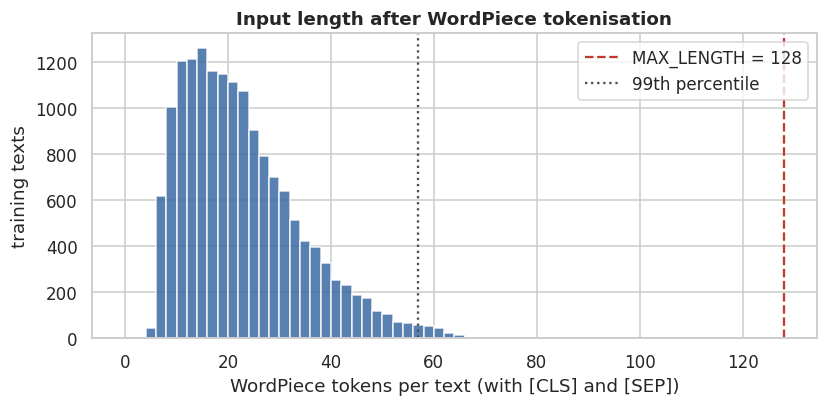

In [8]:
def wordpiece_stats(texts, word_tokens):
    ids = tokenizer(list(texts))["input_ids"]  # includes [CLS] and [SEP]
    lengths = np.array([len(x) for x in ids])
    n_words = np.array([len(t) for t in word_tokens])
    return lengths, {
        "words per text (mean)": n_words.mean(),
        "WordPieces per text (mean, with [CLS]/[SEP])": lengths.mean(),
        "median": np.median(lengths),
        "95th percentile": np.percentile(lengths, 95),
        "99th percentile": np.percentile(lengths, 99),
        "maximum": lengths.max(),
        "pieces per word (fertility)": (lengths - 2).sum() / n_words.sum(),
        "texts > 64 pieces": int((lengths > 64).sum()),
        f"texts > MAX_LENGTH = {MAX_LENGTH}": int((lengths > MAX_LENGTH).sum()),
        "[UNK] tokens": int(sum(seq.count(tokenizer.unk_token_id) for seq in ids)),
    }


wp_lengths, wp_rows = {}, {}
for split, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    wp_lengths[split], wp_rows[split] = wordpiece_stats(X, tokens[split])
display(pd.DataFrame(wp_rows).T.style.format("{:,.2f}"))


def type_coverage(words):
    # Share of word types (and of their running tokens) that are a single WordPiece.
    counts = Counter(words)
    single = {w: len(tokenizer.tokenize(w)) == 1 for w in counts}
    return {
        "word types": len(counts),
        "types that are one WordPiece": np.mean(list(single.values())),
        "tokens that are one WordPiece": sum(c for w, c in counts.items() if single[w]) / sum(counts.values()),
    }


coverage = pd.DataFrame({
    "training words": type_coverage([w for toks in tokens["train"] for w in toks]),
    "test words unseen in training": type_coverage([w for toks in tokens["test"] for w in toks if w not in train_vocab]),
}).T
display(coverage.style.format({"word types": "{:,.0f}", "types that are one WordPiece": "{:.1%}", "tokens that are one WordPiece": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(wp_lengths["train"], bins=np.arange(0, wp_lengths["train"].max() + 3, 2), color="#3B6BA5", alpha=0.85)
ax.axvline(MAX_LENGTH, color="#C0392B", ls="--", label=f"MAX_LENGTH = {MAX_LENGTH}")
ax.axvline(np.percentile(wp_lengths["train"], 99), color="0.3", ls=":", label="99th percentile")
ax.set(xlabel="WordPiece tokens per text (with [CLS] and [SEP])", ylabel="training texts", title="Input length after WordPiece tokenisation")
ax.legend()
savefig(fig, "bert_wordpiece_lengths.png")
plt.show()

**Interpretation.** WordPiece segmentation hardly lengthens the texts (1.06 pieces per word) because the dataset uses common English: 64.3% of the training word types, and 95.8% of the running words, are single WordPieces, and no text produces an `[UNK]` token. The 972 test word types that never occur in the training split are exactly where a word-level model has no feature; 44.8% of them (*elevator*, *refuge*, *treasures*) are whole WordPieces with a pre-trained embedding, and the rest are split into known pieces (*volunteer ##ing*, *bride ##sma ##ids*). The missing apostrophes of the dataset produce artificial pieces (*didn ##t*, *iv ##e*) that the model has to learn to read during fine-tuning.

**Choice of `MAX_LENGTH`.** The longest text of any split is far below 128 WordPieces, so `MAX_LENGTH = 128` truncates no dataset text; it only protects the web app against very long inputs. Self-attention costs $O(n^2)$ per layer, so instead of padding every text to 128, each mini-batch is padded only to its own longest text (**dynamic padding**, below). The attention mask keeps the padding positions out of the softmax.

## 4. Input pipeline

Every split is tokenised once. The dataset returns the unpadded `input_ids`, `token_type_ids` and `attention_mask` of one text plus its label; `DataCollatorWithPadding` pads a mini-batch to its longest member.

In [9]:
class EmotionBertDataset(Dataset):
    """Pre-tokenised texts and labels; padding is added per mini-batch by the collator."""

    def __init__(self, texts, labels, tokenizer, max_length=MAX_LENGTH):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=max_length)
        self.labels = [int(y) for y in labels]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {key: values[i] for key, values in self.encodings.items()}
        item["labels"] = self.labels[i]
        return item


collator = DataCollatorWithPadding(tokenizer=tokenizer)
train_dataset = EmotionBertDataset(X_train, y_train, tokenizer)


def make_loader(dataset, batch_size, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=collator, generator=generator)


example_batch = next(iter(make_loader(train_dataset, batch_size=4, shuffle=False)))
for key, value in example_batch.items():
    print(f"{key:<15} {tuple(value.shape)}")
print("\ninput_ids of the first text:", example_batch["input_ids"][0].tolist())
print("attention_mask            :", example_batch["attention_mask"][0].tolist())

input_ids       (4, 23)
token_type_ids  (4, 23)
attention_mask  (4, 23)
labels          (4,)

input_ids of the first text: [101, 1045, 2134, 2102, 2514, 26608, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask            : [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 5. Full fine-tuning

### 5.1 Training procedure

| Setting | Value | Reason |
|---|---|---|
| Optimiser | AdamW, weight decay 0.01 (not on biases and LayerNorm weights) | decoupled weight decay, as in BERT pre-training |
| Learning rate | grid {2e-5, 3e-5, 5e-5} | the range recommended by Devlin et al. (2019); a larger rate destroys pre-trained knowledge |
| Schedule | linear warm-up over the first 10% of steps, then linear decay to 0 | avoids large early updates while the new linear layer is still random |
| Batch size / epochs | 32 / 4 | Devlin et al. (2019); validation is measured twice per epoch |
| Loss | class-weighted cross-entropy, balanced weights | the same loss as the BiLSTM and `improved_lr`, so the comparison isolates the encoder |
| Regularisation | dropout 0.1 (BERT default), gradient clipping at norm 1.0 | |
| Precision | fp16 mixed precision with loss scaling on the T4 | about 2× faster; evaluation is in fp32 |

**Checkpoint selection.** Validation macro-F1 is computed eight times per run (every half epoch); the checkpoint with the highest value is kept. The learning rate is chosen by the best validation macro-F1 of the seed-42 runs (ties → smaller rate). Fine-tuning is known to vary across random seeds (Dodge et al., 2020): the seed changes the initial classifier weights, the dropout masks and the order of the mini-batches. The selected setting is therefore repeated with seeds 43 and 44, as for the BiLSTM. The test split is scored for every run but plays no part in any selection.

In [10]:
def balanced_class_weights(labels, n_classes=NUM_LABELS):
    # w_c = n / (K * n_c): the same balanced weights as class_weight="balanced" in scikit-learn.
    counts = np.bincount(labels, minlength=n_classes)
    return torch.tensor(len(labels) / (n_classes * counts), dtype=torch.float32)


CLASS_WEIGHTS = balanced_class_weights(y_train)
display(pd.Series(CLASS_WEIGHTS.numpy(), index=LABELS, name="class weight").to_frame().T.round(3))


@dataclass
class FineTuneConfig:
    lr: float = 2e-5
    batch_size: int = 32
    epochs: int = 4
    warmup_ratio: float = 0.1
    weight_decay: float = 0.01
    clip_norm: float = 1.0
    evals_per_epoch: int = 2
    seed: int = SEED


def run_name(cfg):
    return f"lr{cfg.lr:.0e}_seed{cfg.seed}"


def build_optimizer(model, lr, weight_decay):
    # Weight decay on the weight matrices only; biases and LayerNorm parameters are not decayed.
    no_decay = ("bias", "LayerNorm.weight")
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    groups = [
        {"params": [p for n, p in named if not any(nd in n for nd in no_decay)], "weight_decay": weight_decay},
        {"params": [p for n, p in named if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(groups, lr=lr)


def validation_scores(model, criterion):
    # One code path for selection and reporting: fp32 logits from src.bert_infer.predict_logits.
    logits = predict_logits(model, tokenizer, X_val, DEVICE, batch_size=128)
    loss = criterion(torch.from_numpy(logits).to(DEVICE), torch.from_numpy(y_val).to(DEVICE)).item()
    pred = logits.argmax(axis=1)
    return {"val_loss": loss, "val_macro_f1": macro_f1(y_val, pred), "val_accuracy": float(np.mean(pred == y_val))}


def fine_tune(cfg):
    """Fine-tune BertForSequenceClassification; return the best checkpoint (by validation macro-F1) and the history."""
    set_seed(cfg.seed)  # fixes the random initialisation of the new linear layer
    model = BertForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID
    ).to(DEVICE)
    train_loader = make_loader(train_dataset, cfg.batch_size, shuffle=True, seed=cfg.seed)
    optimizer = build_optimizer(model, cfg.lr, cfg.weight_decay)
    total_steps = len(train_loader) * cfg.epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(cfg.warmup_ratio * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    eval_every = math.ceil(len(train_loader) / cfg.evals_per_epoch)

    history, best_f1, best_state, step, window = [], -1.0, None, 0, []
    start = time.perf_counter()
    model.train()
    for epoch in range(1, cfg.epochs + 1):
        for batch_index, batch in enumerate(tqdm(train_loader, desc=f"{run_name(cfg)} epoch {epoch}", leave=False), start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(**batch).logits  # forward pass: [CLS] -> pooler -> dropout -> linear
            loss = criterion(logits.float(), labels)

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()  # back-propagation through the classifier and all 12 layers
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_norm)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            window.append(loss.item())

            if batch_index % eval_every == 0 or batch_index == len(train_loader):
                scores = validation_scores(model, criterion)
                history.append({"step": step, "epoch": step / len(train_loader), "train_loss": float(np.mean(window)),
                                "lr": scheduler.get_last_lr()[0], "seconds": time.perf_counter() - start, **scores})
                window = []
                if scores["val_macro_f1"] > best_f1:
                    best_f1 = scores["val_macro_f1"]
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                model.train()
    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    history["best"] = history["val_macro_f1"] == history["val_macro_f1"].max()
    return model, history

,sadness,joy,love,anger,fear,surprise
class weight,0.572,0.497,2.045,1.235,1.377,4.662


In [11]:
LR_GRID = [2e-5, 3e-5, 5e-5]
EXTRA_SEEDS = [43, 44]
BASE_CONFIG = FineTuneConfig()
RETRAIN = False  # True: train again even if a finished run is found in RUN_DIR


def run_or_load(cfg, keep_checkpoint):
    """Train one configuration, or load its saved results from RUN_DIR."""
    path = RUN_DIR / run_name(cfg)
    files = [path / "history.csv", path / "logits_validation.npy", path / "logits_test.npy"]
    if keep_checkpoint:
        files.append(path / "config.json")
    if all(f.exists() for f in files) and not RETRAIN:
        print(f"loaded finished run {path.name}")
    else:
        print(f"=== training {path.name} ===")
        model, history = fine_tune(cfg)
        path.mkdir(parents=True, exist_ok=True)
        history.to_csv(path / "history.csv", index=False)
        for split, X in [("validation", X_val), ("test", X_test)]:
            np.save(path / f"logits_{split}.npy", predict_logits(model, tokenizer, X, DEVICE, batch_size=128))
        (path / "run_config.json").write_text(json.dumps(asdict(cfg), indent=2))
        if keep_checkpoint:
            save_model(model, tokenizer, path)
        best = history.loc[history["val_macro_f1"].idxmax()]
        print(f"best validation macro-F1 {best['val_macro_f1']:.4f} at epoch {best['epoch']:.1f} | "
              f"{history['seconds'].iloc[-1] / 60:.1f} min")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return {
        "cfg": cfg,
        "path": path,
        "history": pd.read_csv(path / "history.csv"),
        "logits": {split: np.load(path / f"logits_{split}.npy") for split in ("validation", "test")},
    }


grid_runs = {lr: run_or_load(replace(BASE_CONFIG, lr=lr, seed=SEED), keep_checkpoint=True) for lr in LR_GRID}

loaded finished run lr2e-05_seed42
loaded finished run lr3e-05_seed42
loaded finished run lr5e-05_seed42


### 5.2 Learning-rate selection and seed variance

In [12]:
def best_row(run):
    h = run["history"]
    return h.loc[h["val_macro_f1"].idxmax()]


grid_table = pd.DataFrame({
    f"{lr:.0e}": {
        "best val macro-F1": best_row(r)["val_macro_f1"],
        "val accuracy at best": best_row(r)["val_accuracy"],
        "best checkpoint (epoch)": best_row(r)["epoch"],
        "val macro-F1 at end (epoch 4)": r["history"]["val_macro_f1"].iloc[-1],
        "minutes": r["history"]["seconds"].iloc[-1] / 60,
    }
    for lr, r in grid_runs.items()
}).T
grid_table.index.name = "learning rate (seed 42)"
display(grid_table.style.format("{:.4f}").format({"best checkpoint (epoch)": "{:.1f}", "minutes": "{:.1f}"}))

# Highest validation macro-F1 (rounded to 4 decimals); ties -> the smaller learning rate.
BEST_LR = max(LR_GRID, key=lambda lr: (round(best_row(grid_runs[lr])["val_macro_f1"], 4), -lr))
selected_cfg = replace(BASE_CONFIG, lr=BEST_LR, seed=SEED)
print(f"Selected learning rate: {BEST_LR:.0e}")

seed_runs = {SEED: grid_runs[BEST_LR]}
seed_runs.update({s: run_or_load(replace(selected_cfg, seed=s), keep_checkpoint=False) for s in EXTRA_SEEDS})

seed_table = pd.DataFrame({
    seed: {
        "best val macro-F1": best_row(r)["val_macro_f1"],
        "best checkpoint (epoch)": best_row(r)["epoch"],
        "test macro-F1 (reported only)": macro_f1(y_test, r["logits"]["test"].argmax(1)),
        "test accuracy (reported only)": float(np.mean(r["logits"]["test"].argmax(1) == y_test)),
    }
    for seed, r in seed_runs.items()
}).T
seed_table.loc["mean"] = seed_table.loc[list(seed_runs)].mean()
seed_table.loc["sd"] = seed_table.loc[list(seed_runs)].std(ddof=1)
seed_table.index.name = f"seed (lr = {BEST_LR:.0e})"
display(seed_table.round(4))

histories = pd.concat(
    [r["history"].assign(lr=lr, seed=SEED) for lr, r in grid_runs.items()]
    + [r["history"].assign(lr=BEST_LR, seed=s) for s, r in seed_runs.items() if s != SEED],
    ignore_index=True,
)
histories.to_csv(METRICS_DIR / "bert_training_history.csv", index=False)

,best val macro-F1,val accuracy at best,best checkpoint (epoch),val macro-F1 at end (epoch 4),minutes
learning rate (seed 42),,,,,
2e-05,0.915798,0.937000,2.5,0.909037,4.4
3e-05,0.920085,0.940500,2.5,0.913959,4.4
5e-05,0.922426,0.942500,3.0,0.916038,4.4


Selected learning rate: 5e-05
loaded finished run lr5e-05_seed43
loaded finished run lr5e-05_seed44


,best val macro-F1,best checkpoint (epoch),test macro-F1 (reported only),test accuracy (reported only)
seed (lr = 5e-05),,,,
42,0.9224,3.0000,0.8962,0.9300
43,0.9213,3.0000,0.8851,0.9255
44,0.9178,4.0000,0.8993,0.9335
mean,0.9205,3.3333,0.8935,0.9297
sd,0.0024,0.5774,0.0075,0.0040


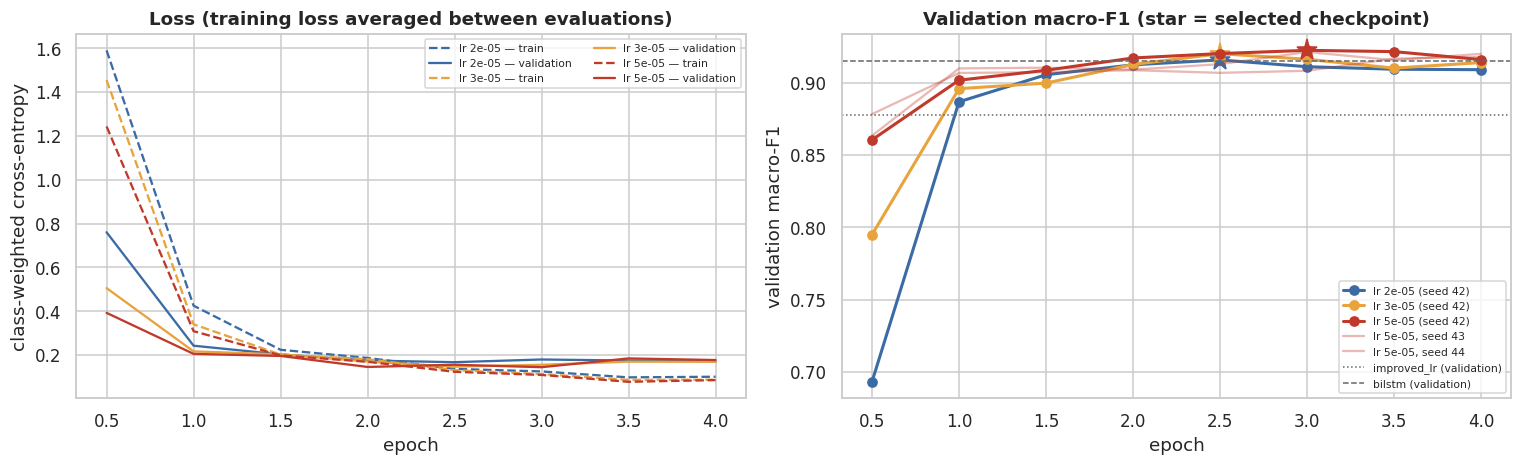

In [13]:
lr_colors = dict(zip(LR_GRID, ["#3B6BA5", "#E8A33D", "#C0392B"]))
reference_val = summary_table(["improved_lr", "bilstm"], split="validation")["macro_f1"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for lr, r in grid_runs.items():
    h = r["history"]
    axes[0].plot(h["epoch"], h["train_loss"], "--", color=lr_colors[lr], label=f"lr {lr:.0e} — train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=lr_colors[lr], label=f"lr {lr:.0e} — validation")
    axes[1].plot(h["epoch"], h["val_macro_f1"], "o-", color=lr_colors[lr], lw=2, label=f"lr {lr:.0e} (seed 42)")
    b = best_row(r)
    axes[1].plot(b["epoch"], b["val_macro_f1"], "*", color=lr_colors[lr], markersize=14)
for s, r in seed_runs.items():
    if s != SEED:
        axes[1].plot(r["history"]["epoch"], r["history"]["val_macro_f1"], "-", color=lr_colors[BEST_LR], alpha=0.35,
                     label=f"lr {BEST_LR:.0e}, seed {s}")
for name, ls in [("improved_lr", ":"), ("bilstm", "--")]:
    axes[1].axhline(reference_val[name], color="0.4", ls=ls, lw=1, label=f"{name} (validation)")
axes[0].set(xlabel="epoch", ylabel="class-weighted cross-entropy", title="Loss (training loss averaged between evaluations)")
axes[1].set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 (star = selected checkpoint)")
axes[0].legend(fontsize=7, ncol=2)
axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout()
savefig(fig, "bert_learning_curves.png")
plt.show()

**Interpretation.** The three learning rates give similar results: the best validation macro-F1 is 0.9158 (2e-5), 0.9201 (3e-5) and 0.9224 (5e-5), a spread of 0.007, about three times the seed standard deviation (0.0024). The selected rate, 5e-5, is the largest value recommended by Devlin et al. (2019); its best checkpoint occurs after three of the four epochs. BERT learns the task quickly: after one epoch, validation macro-F1 is already 0.89–0.90 at every learning rate. The training loss keeps falling towards 0.08, while the validation loss reaches its minimum near epoch 2–3 (0.14–0.17) and then rises again, so selecting the checkpoint on validation matters; the linear decay of the learning rate to zero limits over-fitting in the last epoch.

Across seeds 42–44, the selected setting scores 0.9205 ± 0.0024 on validation and 0.894 ± 0.008 on test (0.885–0.899). The BiLSTM of Step 4 scored 0.891 ± 0.003 on test over its three seeds (`05_bilstm` §7.1), so any difference between the two architectures has to be judged against a seed-to-seed variation of about 0.01.

## 6. Frozen BERT: training the classification layer only

The controlled comparison keeps the architecture of §5 — pre-trained BERT, `[CLS]` → pooler → dropout → linear, the same loss and class weights — and **freezes every BERT parameter**. Only the 4,614 parameters of the linear layer are trained. This is the *feature-based* use of a pre-trained model (Devlin et al., 2019, §5.3): BERT is a fixed feature extractor, and the comparison with §5 measures how much the encoder gains from being adapted to the emotion labels.

Because a frozen BERT in evaluation mode is a deterministic function of its input, its pooled `[CLS]` vector is computed once for every text and the linear layer is trained on these cached vectors. This is mathematically the same as training `BertForSequenceClassification` with `requires_grad = False` on the encoder, only much faster; the check at the end of the section confirms that the full model gives the same logits. With only 4,614 parameters, the layer needs a larger learning rate and more epochs: AdamW with a learning rate from {1e-3, 3e-3, 1e-2}, batch size 64, up to 100 epochs with early stopping on validation macro-F1 (patience 10).

A frozen `[CLS]` vector was pre-trained for next-sentence prediction, not to summarise a sentence's content, so a diagnostic variant (`bert_frozen_mean`) trains the same kind of linear layer on the **mean of the last-layer token vectors** instead. It shows whether a weak frozen result is a property of the frozen encoder or of the `[CLS]` read-out.

In [14]:
set_seed(SEED)
frozen_model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID
).to(DEVICE)
for param in frozen_model.bert.parameters():
    param.requires_grad = False  # freeze embeddings, all 12 layers and the pooler
frozen_model.eval()
n_trainable = sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} of {count(frozen_model):,}")


@torch.no_grad()
def extract_features(bert, texts, batch_size=128):
    """Pooled [CLS] vectors (as used by the classifier) and masked means of the last-layer token vectors."""
    texts = list(texts)
    pooled = np.zeros((len(texts), bert.config.hidden_size), dtype=np.float32)
    mean = np.zeros_like(pooled)
    order = np.argsort([len(t.split()) for t in texts], kind="stable")
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        enc = tokenizer([texts[i] for i in idx], padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
        out = bert(**enc)
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pooled[idx] = out.pooler_output.float().cpu().numpy()
        mean[idx] = ((out.last_hidden_state * mask).sum(1) / mask.sum(1)).float().cpu().numpy()
    return pooled, mean


FEATURE_FILE = RUN_DIR / "frozen_features.npz"
if FEATURE_FILE.exists() and not RETRAIN:
    cached = np.load(FEATURE_FILE)
    features = {kind: {split: cached[f"{kind}_{split}"] for split in ("train", "validation", "test")} for kind in ("pooled", "mean")}
    print(f"loaded {FEATURE_FILE.name}")
else:
    features = {"pooled": {}, "mean": {}}
    for split, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
        features["pooled"][split], features["mean"][split] = extract_features(frozen_model.bert, X)
    np.savez_compressed(FEATURE_FILE, **{f"{k}_{s}": v for k, d in features.items() for s, v in d.items()})
print({kind: features[kind]["train"].shape for kind in features})

trainable parameters: 4,614 of 109,486,854
loaded frozen_features.npz
{'pooled': (16000, 768), 'mean': (16000, 768)}


In [15]:
FROZEN_LR_GRID = [1e-3, 3e-3, 1e-2]


def train_linear_head(head, feats, lr, max_epochs=100, patience=10, batch_size=64, seed=SEED):
    """Train a (dropout -> linear) head on cached BERT features with early stopping on validation macro-F1."""
    set_seed(seed)
    head.to(DEVICE)
    X_tr = torch.from_numpy(feats["train"]).to(DEVICE)
    y_tr = torch.from_numpy(y_train).to(DEVICE)
    X_va = torch.from_numpy(feats["validation"]).to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    generator = torch.Generator().manual_seed(seed)
    best_f1, best_state, history, waited = -1.0, None, [], 0
    for epoch in range(1, max_epochs + 1):
        head.train()
        for idx in torch.randperm(len(X_tr), generator=generator).split(batch_size):
            loss = criterion(head(X_tr[idx]), y_tr[idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        head.eval()
        with torch.no_grad():
            f1 = macro_f1(y_val, head(X_va).argmax(1).cpu().numpy())
        history.append({"epoch": epoch, "val_macro_f1": f1})
        if f1 > best_f1:
            best_f1, best_state, waited = f1, copy.deepcopy(head.state_dict()), 0
        else:
            waited += 1
            if waited >= patience:
                break
    head.load_state_dict(best_state)
    return best_f1, pd.DataFrame(history)


# bert_frozen: the dropout and linear layer of frozen_model itself, so training them completes the classification model.
frozen_head = nn.Sequential(frozen_model.dropout, frozen_model.classifier)
initial_classifier = copy.deepcopy(frozen_model.classifier.state_dict())


def new_mean_head():
    # Same shape and initialisation as BERT's classifier: N(0, 0.02) weights, zero bias.
    set_seed(SEED)
    linear = nn.Linear(frozen_model.config.hidden_size, NUM_LABELS)
    nn.init.normal_(linear.weight, std=frozen_model.config.initializer_range)
    nn.init.zeros_(linear.bias)
    return nn.Sequential(nn.Dropout(frozen_model.config.hidden_dropout_prob), linear)


frozen_rows, frozen_states, frozen_histories = [], {}, []
for kind, model_id in [("pooled", "bert_frozen"), ("mean", "bert_frozen_mean")]:
    for lr in FROZEN_LR_GRID:
        if kind == "pooled":
            frozen_model.classifier.load_state_dict(initial_classifier)
            head = frozen_head
        else:
            head = new_mean_head()
        f1, hist = train_linear_head(head, features[kind], lr)
        frozen_rows.append({"model": model_id, "learning rate": lr, "best val macro-F1": f1,
                            "best epoch": int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"]), "epochs run": len(hist)})
        frozen_states[model_id, lr] = copy.deepcopy(head.state_dict())
        frozen_histories.append(hist.assign(model=model_id, lr=lr))
frozen_table = pd.DataFrame(frozen_rows).set_index(["model", "learning rate"])
display(frozen_table.style.format({"best val macro-F1": "{:.4f}"}))
pd.concat(frozen_histories).to_csv(METRICS_DIR / "bert_frozen_training_history.csv", index=False)

frozen_best_lr = {}
for model_id in ("bert_frozen", "bert_frozen_mean"):
    sub = frozen_table.loc[model_id]["best val macro-F1"].round(4)
    frozen_best_lr[model_id] = min(sub[sub == sub.max()].index)  # ties -> smaller learning rate
print("selected learning rates:", {m: f"{lr:.0e}" for m, lr in frozen_best_lr.items()})

frozen_head.load_state_dict(frozen_states["bert_frozen", frozen_best_lr["bert_frozen"]])
mean_head = new_mean_head()
mean_head.load_state_dict(frozen_states["bert_frozen_mean", frozen_best_lr["bert_frozen_mean"]])
mean_head.to(DEVICE).eval()
frozen_head.eval()

# Check: the complete BertForSequenceClassification (frozen encoder + trained linear layer) gives the same logits
# as the linear layer applied to the cached pooled vectors.
full_forward = predict_logits(frozen_model, tokenizer, X_val, DEVICE, batch_size=128)
with torch.no_grad():
    cached_forward = frozen_model.classifier(torch.from_numpy(features["pooled"]["validation"]).to(DEVICE)).cpu().numpy()
print(f"max |logit difference| full model vs cached features: {np.abs(full_forward - cached_forward).max():.1e} | "
      f"label agreement {np.mean(full_forward.argmax(1) == cached_forward.argmax(1)):.4f}")

selected learning rates: {'bert_frozen': '3e-03', 'bert_frozen_mean': '1e-02'}
max |logit difference| full model vs cached features: 2.2e-06 | label agreement 1.0000


## 7. Test evaluation

### 7.1 Scores

The selected fine-tuned run (learning rate from §5.2, seed 42, best checkpoint) and the two frozen variants are scored through `src/evaluate.py` on validation and test. The variant with the higher validation macro-F1 is saved again under the role name `bert`, which the web service uses.

In [16]:
with torch.no_grad():
    frozen_logits = {
        "bert_frozen": {s: frozen_model.classifier(torch.from_numpy(features["pooled"][s]).to(DEVICE)).cpu().numpy()
                        for s in ("validation", "test")},
        "bert_frozen_mean": {s: mean_head(torch.from_numpy(features["mean"][s]).to(DEVICE)).cpu().numpy()
                             for s in ("validation", "test")},
    }
logits = {"bert_finetuned": grid_runs[BEST_LR]["logits"], **frozen_logits}
best_ft = best_row(grid_runs[BEST_LR])
NOTES = {
    "bert_finetuned": (f"bert-base-uncased, full fine-tuning; [CLS] -> pooler -> dropout 0.1 -> linear; class-weighted CE; "
                       f"AdamW lr={BEST_LR:.0e}, wd 0.01, warm-up 10% + linear decay, batch {selected_cfg.batch_size}, {selected_cfg.epochs} epochs, fp16 on GPU; "
                       f"best checkpoint at epoch {best_ft['epoch']:.1f} by validation macro-F1; seed {SEED}"),
    "bert_frozen": (f"bert-base-uncased frozen; only the linear layer on the pooled [CLS] vector trained; class-weighted CE; "
                    f"AdamW lr={frozen_best_lr['bert_frozen']:.0e}; early stopping on validation macro-F1; seed {SEED}"),
    "bert_frozen_mean": (f"bert-base-uncased frozen; linear layer on the mean of the last-layer token vectors; class-weighted CE; "
                         f"AdamW lr={frozen_best_lr['bert_frozen_mean']:.0e}; early stopping on validation macro-F1; seed {SEED}"),
}

preds, probas = {"validation": {}, "test": {}}, {"validation": {}, "test": {}}
for model_id, by_split in logits.items():
    for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        proba = softmax_with_temperature(by_split[split])
        pred = proba.argmax(axis=1)
        evaluate(model_id, y, pred, split=split, y_proba=proba, texts=X, notes=NOTES[model_id])
        preds[split][model_id], probas[split][model_id] = pred, proba

selected_id = max(["bert_finetuned", "bert_frozen"], key=lambda m: macro_f1(y_val, preds["validation"][m]))
DISPLAY_NAMES["bert"] = f"BERT [selected: {'fine-tuned' if selected_id == 'bert_finetuned' else 'frozen'}]"
for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    evaluate("bert", y, preds[split][selected_id], split=split, y_proba=probas[split][selected_id], texts=X,
             notes=f"role name: {selected_id} (selected by validation macro-F1)", verbose=False)
    preds[split]["bert"], probas[split]["bert"] = preds[split][selected_id], probas[split][selected_id]
print(f"role name 'bert' -> {selected_id}")

bert_finetuned [validation]  accuracy=0.9425  macro-F1=0.9224  weighted-F1=0.9434
bert_finetuned [test]  accuracy=0.9300  macro-F1=0.8962  weighted-F1=0.9321
bert_frozen [validation]  accuracy=0.4880  macro-F1=0.4196  weighted-F1=0.5087
bert_frozen [test]  accuracy=0.4830  macro-F1=0.4184  weighted-F1=0.5022
bert_frozen_mean [validation]  accuracy=0.6185  macro-F1=0.5415  weighted-F1=0.6224
bert_frozen_mean [test]  accuracy=0.6085  macro-F1=0.5296  weighted-F1=0.6142
role name 'bert' -> bert_finetuned


In [17]:
TABLE_MODELS = ["tfidf_lr", "improved_lr", "bilstm", "bert_frozen", "bert_frozen_mean", "bert_finetuned"]
test_preds = {**reference_preds["test"], **preds["test"]}

print("Validation split")
display(summary_table(TABLE_MODELS, split="validation").rename(index=DISPLAY_NAMES).round(3))

test_table = summary_table(TABLE_MODELS, split="test")
ci = {name: bootstrap_ci(y_test, test_preds[name]) for name in TABLE_MODELS}
test_table.insert(2, "macro_f1_ci95", [f"[{ci[n][0]:.3f}, {ci[n][1]:.3f}]" for n in TABLE_MODELS])
print("Test split (final evaluation)")
display(test_table.rename(index=DISPLAY_NAMES).round(3))

Validation split


,accuracy,macro_f1,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,
TF-IDF + LR,0.894,0.865,0.894,0.912,0.924,0.826,0.897,0.834,0.797
Improved sparse LR,0.899,0.878,0.900,0.924,0.918,0.850,0.905,0.846,0.825
BiLSTM [selected],0.941,0.915,0.942,0.972,0.959,0.888,0.948,0.881,0.841
BERT frozen ([CLS] pooler) + linear,0.488,0.420,0.509,0.559,0.630,0.302,0.409,0.387,0.232
BERT frozen (token mean) + linear,0.618,0.542,0.622,0.660,0.738,0.429,0.530,0.517,0.376
BERT fine-tuned,0.942,0.922,0.943,0.969,0.956,0.885,0.951,0.902,0.872


Test split (final evaluation)


,accuracy,macro_f1,macro_f1_ci95,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,,
TF-IDF + LR,0.882,0.832,"[0.808, 0.853]",0.880,0.919,0.910,0.761,0.876,0.833,0.694
Improved sparse LR,0.885,0.843,"[0.820, 0.862]",0.888,0.925,0.910,0.774,0.886,0.860,0.701
BiLSTM [selected],0.932,0.894,"[0.873, 0.911]",0.933,0.965,0.953,0.861,0.936,0.885,0.764
BERT frozen ([CLS] pooler) + linear,0.483,0.418,"[0.394, 0.441]",0.502,0.528,0.621,0.292,0.413,0.400,0.257
BERT frozen (token mean) + linear,0.608,0.530,"[0.503, 0.555]",0.614,0.661,0.731,0.388,0.480,0.517,0.400
BERT fine-tuned,0.930,0.896,"[0.877, 0.911]",0.932,0.969,0.944,0.848,0.941,0.893,0.783


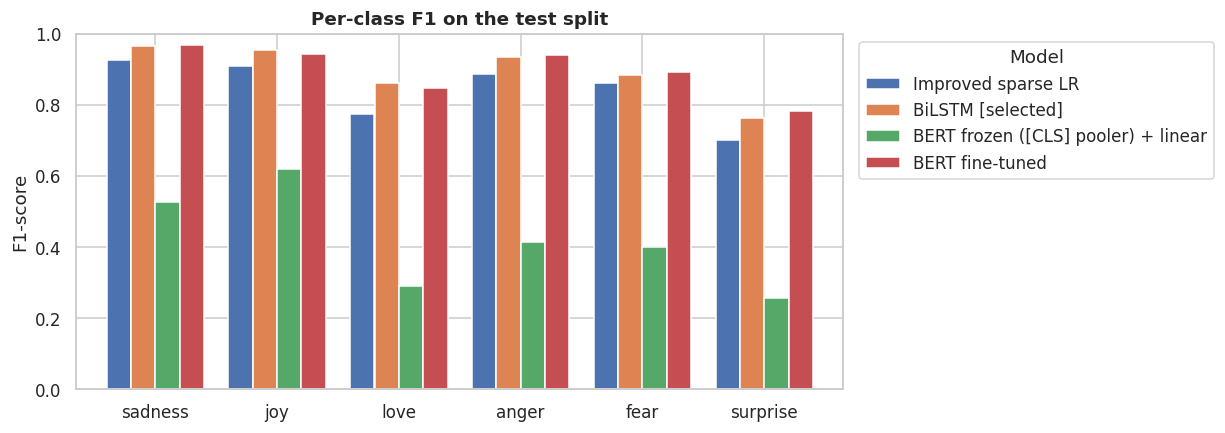

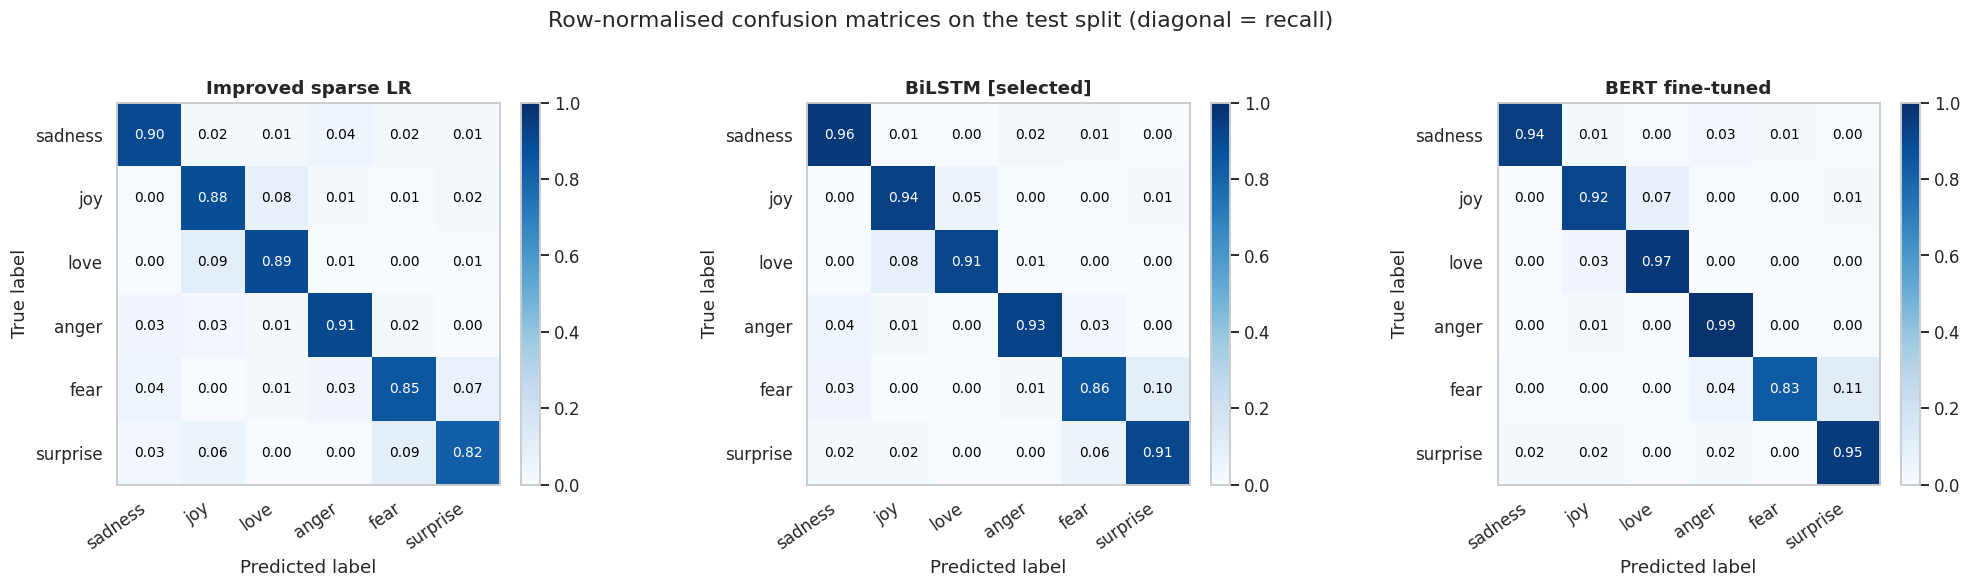

In [18]:
ax = plot_per_class_f1(
    test_table.drop(columns="macro_f1_ci95").loc[["improved_lr", "bilstm", "bert_frozen", "bert_finetuned"]].rename(index=DISPLAY_NAMES),
    title="Per-class F1 on the test split",
    save_as="bert_per_class_f1.png",
)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, name in zip(axes, ["improved_lr", "bilstm", "bert_finetuned"]):
    plot_confusion_matrix(y_test, test_preds[name], title=DISPLAY_NAMES[name], ax=ax)
fig.suptitle("Row-normalised confusion matrices on the test split (diagonal = recall)", y=1.02)
fig.tight_layout()
savefig(fig, "bert_confusion_matrices.png")
plt.show()

**Interpretation.** Fine-tuned BERT and the BiLSTM have almost the same per-class profile; no per-class F1 differs by more than 0.02. BERT is slightly better on the minority class *surprise* (0.783 vs 0.764) and slightly worse on *love* (0.848 vs 0.861). The confusion matrices show that BERT trades precision for recall on *love*: it finds 96.9% of the love texts (BiLSTM 91.2%) but labels 7.2% of the joy texts as love. *love* vs *joy* remains the hardest boundary for every model in the project, followed by *fear* → *surprise* (11.2% of the fear texts for BERT).

### 7.2 Significance of the controlled comparisons

Paired tests on the 2,000 test texts, as in Steps 2–4: McNemar's test on the texts where exactly one model is correct, and a paired bootstrap of the macro-F1 difference (2,000 resamples), Holm-adjusted for the three comparisons. The tests treat each trained model as fixed; the seed spread in §5.2 adds the variance due to training.

1. **Frozen → fine-tuned BERT** (same architecture, data, loss and linear layer): the effect of adapting the encoder.
2. **Best classical model → BERT** (`improved_lr`, Step 3).
3. **BiLSTM → BERT**: recurrent composition of static GloVe vectors (Step 4) vs contextual self-attention pre-trained on 3.3B words.

In [19]:
COMPARISONS = [
    ("bert_frozen", "bert_finetuned", "frozen → fine-tuned BERT (same architecture and classifier)"),
    ("improved_lr", "bert", "best classical model (Step 3) → selected BERT"),
    ("bilstm", "bert", "BiLSTM on fine-tuned GloVe (Step 4) → selected BERT"),
]
rows = []
for a, b, question in COMPARISONS:
    mc = mcnemar_test(y_test, test_preds[a], test_preds[b])
    bs = paired_bootstrap(y_test, test_preds[a], test_preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{DISPLAY_NAMES[a]} → {DISPLAY_NAMES[b]}",
        "question": question,
        "b (only A correct)": mc["b"],
        "c (only B correct)": mc["c"],
        "McNemar p": mc["p_value"],
        "Δ macro-F1": bs["delta"],
        "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
    })
significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.insert(5, "Holm p", holm(significance["McNemar p"]))
significance.to_csv(METRICS_DIR / "significance_bert_test.csv")
display(significance.style.format({"McNemar p": "{:.2e}", "Holm p": "{:.2e}", "Δ macro-F1": "{:+.3f}"}))

,question,b (only A correct),c (only B correct),McNemar p,Δ macro-F1,Holm p,95% CI of Δ
comparison (A → B),,,,,,,
BERT frozen ([CLS] pooler) + linear → BERT fine-tuned,frozen → fine-tuned BERT (same architecture and classifier),49,943,7.74e-177,+0.478,2.32e-176,"[+0.450, +0.503]"
Improved sparse LR → BERT [selected: fine-tuned],best classical model (Step 3) → selected BERT,42,132,1.51e-11,+0.053,3.02e-11,"[+0.035, +0.072]"
BiLSTM [selected] → BERT [selected: fine-tuned],BiLSTM on fine-tuned GloVe (Step 4) → selected BERT,55,52,8.47e-01,+0.002,8.47e-01,"[-0.013, +0.017]"


**Interpretation.**

* **BERT vs the classical models.** Fine-tuned BERT reaches 0.930 accuracy and 0.896 macro-F1 [0.877, 0.911]. It is significantly better than the best classical model: 132 test texts are classified correctly only by BERT and 42 only by `improved_lr` (Δ macro-F1 = +0.053 [+0.035, +0.072], Holm p = 3e-11).
* **BERT vs the BiLSTM.** BERT is **not** significantly better than the BiLSTM on fine-tuned GloVe vectors: the two models disagree on almost the same number of texts in each direction (52 vs 55, p = 0.85), and Δ = +0.002 [−0.013, +0.017] is smaller than the seed-to-seed variation of either model (§5.2). On this dataset, a 110M-parameter pre-trained Transformer and an 8.5M-parameter BiLSTM are statistically indistinguishable in accuracy.
* **Fine-tuning vs a frozen encoder.** With the same architecture, data, loss and linear layer, updating the encoder adds +0.478 macro-F1 [+0.450, +0.503] (943 texts gained, 49 lost). A frozen BERT with a trained linear layer reaches only 0.418, below the Naive Bayes baseline (0.695). Two reasons explain the gap. First, the pooled `[CLS]` vector of the pre-trained model was trained for next-sentence prediction, a task about the coherence of a sentence pair rather than the content of one sentence: averaging the last-layer token vectors instead (`bert_frozen_mean`) raises frozen macro-F1 to 0.530. Second, even the token mean stays below averaged GloVe vectors + LR (0.601): pre-training gives BERT general knowledge of syntax and word meaning, but the emotion distinction has to be written into the encoder by the labelled data, which a linear layer with 4,614 parameters on top of fixed vectors cannot do. Freezing behaves very differently for static embeddings: a frozen GloVe layer cost the BiLSTM little (0.888 vs 0.894, not significant) because the recurrent layers above it could still learn the task.

In [20]:
# Texts on which exactly one of BiLSTM and BERT is correct (a sample of each kind).
disagree = pd.DataFrame({"text": X_test, "gold": [LABELS[i] for i in y_test],
                         "BiLSTM": [LABELS[i] for i in test_preds["bilstm"]], "BERT": [LABELS[i] for i in test_preds["bert"]]})
only_bert = (test_preds["bert"] == y_test) & (test_preds["bilstm"] != y_test)
only_bilstm = (test_preds["bert"] != y_test) & (test_preds["bilstm"] == y_test)
with pd.option_context("display.max_colwidth", 110):
    print(f"only BERT correct: {only_bert.sum()} texts")
    display(disagree[only_bert].sample(min(8, only_bert.sum()), random_state=SEED))
    print(f"only BiLSTM correct: {only_bilstm.sum()} texts")
    display(disagree[only_bilstm].sample(min(8, only_bilstm.sum()), random_state=SEED))

only BERT correct: 52 texts


,text,gold,BiLSTM,BERT
625,i am feeling overwhelmed by trying to do it all that i think on the women before me,surprise,fear,surprise
1397,i have come from the summer time and feeling like coach hated me,anger,sadness,anger
1780,when i learnt that my best friend had failed the exams,anger,sadness,anger
419,i guess feelings aren t meant to be inhibited or prohibited,fear,sadness,fear
1607,i felt it had a slight bitterness in the finish that detracted from its oily mouthfeel and sweet entry,joy,love,joy
131,im feeling generous today heres one more you may have already seen but is good for a chuckle,love,joy,love
518,i watched the news at the tv,anger,sadness,anger
1936,im polyamorous something im starting to feel truly accepted for being,love,joy,love


only BiLSTM correct: 55 texts


,text,gold,BiLSTM,BERT
1330,i know she shes the only one who provides income to my family right now but it feels like shes putting it ...,joy,joy,love
251,i hope everyone can help with charity work without feeling stressed about such things,sadness,sadness,anger
1360,i have a family i can feel passionate about and completely comfortable with,joy,joy,love
540,i feel like alcoholism is something that is widely accepted as the norm in gay culture,joy,joy,love
756,getting sent on a company expense trip to another state to work for a week at that plan,joy,joy,anger
1772,i have this grave feeling it will not be back until tomorrow and strangely enough i have accepted it,joy,joy,love
1552,i am finally starting to feel like i have a real life here in san vicente and i am no longer on a strange ...,fear,fear,surprise
897,ive been soo excited for him to feel and it was amazing,joy,joy,surprise


**Interpretation.** The two models also make largely the same mistakes. They give the same label to 94.5% of the test texts; 85 texts are misclassified by both, and for 82 of them (96%) both models choose the *same* wrong label. Errors on which two very different encoders agree point to the data rather than to a model: the labels were derived from emotion hashtags (distant supervision), and a text such as *i feel like alcoholism is something that is widely accepted as the norm in gay culture* (gold: joy) carries a label that no reading of the text supports. Even if one model were right whenever the other is, accuracy would only rise to 0.958, which suggests that both models are close to the ceiling allowed by the label noise. These shared errors are analysed in `08_error_analysis`.

## 8. Where does BERT gain?

### 8.1 Text length, negation and unseen words

The same test slices as in `05_bilstm` §8.2. Static-vector models lost most on long texts and texts with a word unseen in training; the negation slice is where composition matters most.

In [21]:
test_lengths = np.array([len(toks) for toks in tokens["test"]])
length_bins = pd.qcut(test_lengths, 4)
negation_mask = has_negation(X_test)
has_unseen = unseen_word_mask(X_test, train_vocab)

slices = [(f"length {int(np.floor(iv.left)) + 1}–{iv.right:.0f}", length_bins == iv) for iv in length_bins.categories]
slices += [("with negation cue", negation_mask), ("without negation cue", ~negation_mask),
           ("contains an unseen word", has_unseen), ("all words seen in training", ~has_unseen)]
SLICE_MODELS = ["improved_lr", "bilstm", "bert_frozen", "bert_finetuned"]

slice_rows = []
for slice_name, mask in slices:
    row = {"test slice": slice_name, "n": int(mask.sum())}
    row.update({DISPLAY_NAMES[m]: macro_f1(y_test[mask], test_preds[m][mask]) for m in SLICE_MODELS})
    bs = paired_bootstrap(y_test[mask], test_preds["bilstm"][mask], test_preds["bert"][mask], n_boot=2000, seed=SEED)
    row["Δ bert − bilstm"] = bs["delta"]
    row["95% CI of Δ"] = f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]"
    slice_rows.append(row)
slice_table = pd.DataFrame(slice_rows).set_index("test slice")
slice_table.to_csv(METRICS_DIR / "slices_bert_test.csv")
display(slice_table.round(3))

,n,Improved sparse LR,BiLSTM [selected],BERT frozen ([CLS] pooler) + linear,BERT fine-tuned,Δ bert − bilstm,95% CI of Δ
test slice,,,,,,,
length 3–10,501,0.892,0.888,0.504,0.893,0.004,"[-0.023, +0.032]"
length 11–17,531,0.877,0.897,0.436,0.895,-0.003,"[-0.029, +0.026]"
length 18–26,507,0.838,0.875,0.405,0.893,0.018,"[-0.013, +0.052]"
length 27–61,461,0.758,0.912,0.321,0.905,-0.008,"[-0.047, +0.029]"
with negation cue,570,0.813,0.906,0.340,0.885,-0.020,"[-0.048, +0.005]"
without negation cue,1430,0.855,0.890,0.449,0.901,0.011,"[-0.007, +0.030]"
contains an unseen word,630,0.835,0.915,0.406,0.921,0.006,"[-0.021, +0.035]"
all words seen in training,1370,0.845,0.880,0.419,0.882,0.002,"[-0.016, +0.021]"


**Interpretation.** No test slice shows a significant difference between BERT and the BiLSTM (every 95% interval contains 0). Both neural models are equally robust to text length: macro-F1 stays between 0.89 and 0.91 in every length quartile, whereas the sparse model drops from 0.892 to 0.758. BERT is not better on texts that contain a word unseen in training (Δ +0.006 [−0.021, +0.035]): WordPiece guarantees that no input is out of vocabulary (§3), but the BiLSTM already handles these words through GloVe, which covers 88% of them (`04_static_embeddings` §3). On texts with a negation cue BERT is, if anything, slightly worse (Δ −0.020 [−0.048, +0.005]). Bidirectional self-attention can relate *not* to the word in its scope, but the 4,527 training texts with a negation cue are enough for the BiLSTM to learn the common patterns as well.

### 8.2 Minimal pairs

The hand-written pairs of `05_bilstm` §8.3, which differ only in word order or in a negation. They illustrate behaviour; the systematic behavioural tests follow in `08_error_analysis`.

In [ ]:
from src.bilstm import load_checkpoint, predict_proba as bilstm_predict_proba

bilstm_model, bilstm_vocab, _ = load_checkpoint(MODELS_DIR / "bilstm" / "bilstm.pt", DEVICE)
best_model = BertForSequenceClassification.from_pretrained(str(grid_runs[BEST_LR]["path"])).to(DEVICE).eval()

PAIRS = [
    ("i was scared at first but now i feel relieved and happy", "i was relieved and happy at first but now i feel scared"),
    ("i am not angry just really surprised", "i am not surprised just really angry"),
    ("i feel happy", "i do not feel happy"),
    ("i feel loved", "i don t feel loved anymore"),
]
probe_texts = [t for pair in PAIRS for t in pair]
probe_models = {
    "bilstm": lambda texts: bilstm_predict_proba(bilstm_model, bilstm_vocab, texts, DEVICE).argmax(1),
    "bert_frozen": lambda texts: predict_logits(frozen_model, tokenizer, texts, DEVICE).argmax(1),
    "bert_finetuned": lambda texts: predict_logits(best_model, tokenizer, texts, DEVICE).argmax(1),
}
probe = pd.DataFrame({DISPLAY_NAMES[m]: [LABELS[i] for i in f(probe_texts)] for m, f in probe_models.items()}, index=probe_texts)
probe.insert(0, "pair", [f"{k // 2 + 1}{'ab'[k % 2]}" for k in range(len(probe_texts))])
with pd.option_context("display.max_colwidth", 80):
    display(probe)

## 9. Probability quality

The web application displays class probabilities. **Temperature scaling** (Guo et al., 2017) divides the logits by one scalar $T$ fitted on the validation split by minimising the log-loss; it changes the confidence, never the predicted label. The fitted $T$ is stored in `models/bert/training_info.json` and applied by `src/bert_infer.py`.

In [ ]:
temperatures, calibration_rows = {}, []
for model_id in ("bert_frozen", "bert_finetuned"):
    fit_T = minimize_scalar(
        lambda T: log_loss(y_val, softmax_with_temperature(logits[model_id]["validation"], T), labels=LABEL_IDS),
        bounds=(0.05, 10.0), method="bounded",
    )
    temperatures[model_id] = float(fit_T.x)
    for label, T in [("raw", 1.0), ("temperature-scaled", fit_T.x)]:
        proba = softmax_with_temperature(logits[model_id]["test"], T)
        confidence, correct = proba.max(axis=1), proba.argmax(axis=1) == y_test
        calibration_rows.append({
            "model": DISPLAY_NAMES[model_id], "probabilities": label, "T": T,
            "test log-loss": log_loss(y_test, proba, labels=LABEL_IDS), "mean confidence": confidence.mean(),
            "accuracy": correct.mean(), "wrong with confidence > 0.9": int(np.sum(~correct & (confidence > 0.9))),
        })
temperatures["bert"] = temperatures[selected_id]
(METRICS_DIR / "temperature_bert.json").write_text(json.dumps(temperatures, indent=2))
display(pd.DataFrame(calibration_rows).set_index(["model", "probabilities"]).round(3))

**Interpretation.** BERT gives the best-calibrated probabilities of the project. Its raw test log-loss is 0.164, against 0.249 for the BiLSTM and 0.474 for `improved_lr`, and only 32 test texts are misclassified with a confidence above 0.9 (BiLSTM: 73). The fitted temperature T = 1.32 makes the probabilities slightly less confident, reducing the log-loss to 0.149 and the confident errors to 12 without changing any label. For the web application, which shows probabilities and compares models side by side, this is the strongest practical argument for BERT.

## 10. Saving the model to `models/bert/`

`save_model` (in `src/bert_infer.py`) writes the weights (`model.safetensors`, about 440 MB), the configuration with the label names (`config.json`), the tokenizer files and `training_info.json` (hyper-parameters, selection results, the temperature and the library versions). A model card (`README.md`) describes the model on the Hugging Face Hub. Only `README.md` and `training_info.json` are committed to GitHub; the weights are too large for GitHub and are backed up on the Hub in §14.

The check reloads the folder on the CPU through `BertEmotionClassifier`, as the FastAPI service on the Mac will, and compares its predictions with the GPU run.

In [24]:
test_scores = summary_table(["bert"], split="test").iloc[0]
val_scores = summary_table(["bert"], split="validation").iloc[0]
training_info = {
    "model_id": selected_id,
    "base_model": MODEL_NAME,
    "labels": LABELS,
    "max_length": MAX_LENGTH,
    "fine_tuning": {**asdict(selected_cfg), "lr_grid": LR_GRID, "loss": "class-weighted cross-entropy (balanced)",
                    "optimizer": "AdamW", "schedule": "linear warm-up + linear decay", "mixed_precision": USE_AMP},
    "selection": {"metric": "validation macro-F1", "best_epoch": float(best_ft["epoch"]), "best_step": int(best_ft["step"]),
                  "validation_macro_f1": float(val_scores["macro_f1"]), "validation_accuracy": float(val_scores["accuracy"])},
    "test": {"macro_f1": float(test_scores["macro_f1"]), "accuracy": float(test_scores["accuracy"])},
    "temperature": temperatures["bert"],
    "seed": SEED,
    "trained_on": GPU_NAME,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
save_model(best_model, tokenizer, BERT_DIR, training_info)

per_class = pd.DataFrame(json.loads((METRICS_DIR / "bert__test.json").read_text())["per_class"]).T
label_list = ", ".join(LABELS)
lr_list = ", ".join(f"{lr:.0e}" for lr in LR_GRID)
per_class_list = ", ".join(f"{c} {per_class.loc[c, 'f1']:.3f}" for c in LABELS)
best_epoch, test_acc, test_f1 = best_ft["epoch"], test_scores["accuracy"], test_scores["macro_f1"]
batch_size, n_epochs = selected_cfg.batch_size, selected_cfg.epochs
model_card = f"""---
language: en
license: apache-2.0
library_name: transformers
pipeline_tag: text-classification
base_model: bert-base-uncased
datasets:
- dair-ai/emotion
metrics:
- accuracy
- f1
---

# Emotion Mirror · BERT (CBS4702 Final Project)

`bert-base-uncased` fine-tuned on [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion) (16,000 training texts)
to classify short English texts into six emotions: {label_list}.
Code and full evaluation: https://github.com/Cecile1015/emotion-mirror-cbs4702 (`notebooks/06_bert.ipynb`).

## Training

Full fine-tuning, `[CLS]` -> pooler -> dropout -> linear; class-weighted cross-entropy; AdamW, learning rate {BEST_LR:.0e}
(selected from {lr_list} on validation macro-F1), 10% linear warm-up, batch size {batch_size},
{n_epochs} epochs; checkpoint selected by validation macro-F1 (epoch {best_epoch:.1f}); seed {SEED}.

## Results (official test split, 2,000 texts)

| Metric | Value |
|---|---|
| Accuracy | {test_acc:.3f} |
| Macro-F1 | {test_f1:.3f} |

Per-class F1: {per_class_list}.

Probabilities are calibrated by temperature scaling, T = {temperatures['bert']:.3f} (stored in `training_info.json`;
apply `softmax(logits / T)`).

## Limitations

The dataset consists of English Twitter messages built around templates such as "i feel ...". The model recognises the
emotion *expressed* in a text, not the writer's actual emotional state, and it is a course project, not a clinical or
psychological instrument.
"""
(BERT_DIR / "README.md").write_text(model_card, encoding="utf-8")
print(f"saved to {BERT_DIR}:")
for f in sorted(BERT_DIR.iterdir()):
    print(f"  {f.name:<28} {f.stat().st_size / 2**20:8.2f} MB")

saved to /content/emotion-mirror-cbs4702/models/bert:
  README.md                        0.00 MB
  config.json                      0.00 MB
  model.safetensors              417.68 MB
  tokenizer.json                   0.68 MB
  tokenizer_config.json            0.00 MB
  training_info.json               0.00 MB
  vocab.txt                        0.22 MB


In [25]:
clf = BertEmotionClassifier(BERT_DIR, device="cpu")
service_proba = clf.predict_proba(X_test)
gpu_proba = softmax_with_temperature(logits[selected_id]["test"], temperatures["bert"])
print(f"reloaded on CPU | temperature {clf.temperature:.3f} | label agreement with the {GPU_NAME} run: "
      f"{np.mean(service_proba.argmax(1) == preds['test']['bert']):.4f} | max |Δp| = {np.abs(service_proba - gpu_proba).max():.1e}")

demo = ["i feel so lonely without you", "i am thrilled about the trip", "i was shocked by the news", "i feel forlorn"]
demo_proba = pd.DataFrame(clf.predict_proba(demo), columns=LABELS, index=demo).round(3)
demo_proba["prediction"] = [LABELS[i] for i in demo_proba[LABELS].to_numpy().argmax(1)]
demo_proba

reloaded on CPU | temperature 1.320 | label agreement with the Tesla T4 run: 1.0000 | max |Δp| = 3.4e-06


,sadness,joy,love,anger,fear,surprise,prediction
i feel so lonely without you,0.992,0.001,0.002,0.002,0.001,0.001,sadness
i am thrilled about the trip,0.001,0.993,0.003,0.001,0.001,0.001,joy
i was shocked by the news,0.002,0.003,0.001,0.002,0.003,0.989,surprise
i feel forlorn,0.992,0.001,0.001,0.001,0.002,0.002,sadness


## 11. What does self-attention look at?

`BertEmotionClassifier.explain` returns the attention weights $\alpha_{ij}$ of all 12 layers × 12 heads. Two summaries are shown:

* **`[CLS]` attention in the last layer**, averaged over the heads: the weights with which the `[CLS]` position — the input of the classifier — reads the other tokens in layer 12.
* **Attention rollout** (Abnar & Zuidema, 2020): the head-averaged attention matrices of all layers, each mixed with the identity for the residual connection, multiplied from layer 1 to layer 12. It estimates how much each *input* token flows into the final `[CLS]` vector.

Attention weights show how information is routed, not which words cause the decision: different attention patterns can lead to the same prediction (Jain & Wallace, 2019), and much attention goes to special tokens (Clark et al., 2019; §11.2). They are an illustration for the web app, not an explanation method.

In [ ]:
sentence = "i was scared at first but now i feel relieved and happy"
exp = clf.explain(sentence)
print(f"prediction: {exp.label} ({exp.probabilities[exp.label]:.3f}) | attention tensor (layers, heads, seq, seq): {exp.attentions.shape}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
n_layers = exp.attentions.shape[0]
for ax, layer in zip(axes, [0, n_layers // 2 - 1, n_layers - 1]):
    sns.heatmap(exp.attentions[layer].mean(axis=0), xticklabels=exp.tokens, yticklabels=exp.tokens,
                cmap="Blues", vmin=0, square=True, cbar=False, ax=ax)
    ax.set_title(f"layer {layer + 1}, mean over {exp.attentions.shape[1]} heads")
    ax.set_xlabel("attended token j (key)")
    ax.set_ylabel("attending token i (query)")
    ax.tick_params(axis="x", rotation=90)
fig.suptitle(f"Self-attention weights α_ij — \"{sentence}\"", y=1.02)
fig.tight_layout()
savefig(fig, "bert_attention_heatmaps.png")
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, text in zip(axes, PAIRS[0]):
    e = clf.explain(text)
    x = np.arange(len(e.words))
    ax.bar(x - 0.2, e.word_cls_attention, 0.4, color="#3B6BA5", label="[CLS] attention, last layer")
    ax.bar(x + 0.2, e.word_rollout, 0.4, color="#E8A33D", label="attention rollout")
    ax.set_xticks(x, e.words)
    ax.set_ylabel("attention mass")
    ax.set_title(f"\"{text}\" → {e.label} ({e.probabilities[e.label]:.2f})", fontsize=10)
axes[0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "bert_attention_minimal_pair.png")
plt.show()

### 11.2 Where does the attention mass go, layer by layer?

Averaged over 200 validation texts: the share of attention that each layer gives to `[CLS]`, to `[SEP]` and to the word tokens.

In [ ]:
rng = np.random.default_rng(SEED)
sample_texts = [X_val[i] for i in rng.choice(len(X_val), size=200, replace=False)]
explainer = BertEmotionClassifier(BERT_DIR, device=DEVICE)  # same model on the GPU, for speed
shares = []
for text in tqdm(sample_texts, desc="attention statistics", leave=False):
    e = explainer.explain(text)
    a = e.attentions.mean(axis=1)  # (layers, seq, seq), averaged over heads
    is_cls = np.array([t == "[CLS]" for t in e.tokens])
    is_sep = np.array([t == "[SEP]" for t in e.tokens])
    shares.append(np.stack([a[:, :, is_cls].sum(-1).mean(-1), a[:, :, is_sep].sum(-1).mean(-1),
                            a[:, :, ~(is_cls | is_sep)].sum(-1).mean(-1)], axis=1))
share_table = pd.DataFrame(np.mean(shares, axis=0), columns=["[CLS]", "[SEP]", "word tokens"],
                           index=pd.RangeIndex(1, len(shares[0]) + 1, name="layer"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
share_table.plot(kind="bar", stacked=True, color=["#6A4C93", "#C0392B", "#2A9D8F"], ax=ax, width=0.8)
ax.set(ylabel="share of attention", title="Attention mass by target token type (200 validation texts)")
ax.tick_params(axis="x", rotation=0)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig(fig, "bert_attention_special_tokens.png")
plt.show()
display(share_table.T.round(2))

**Interpretation.** In layers 2–3 about 40% of the attention mass goes to `[CLS]`, and in layers 5–11 50–65% goes to `[SEP]`. Clark et al. (2019) interpret this pattern as a "no-operation": when a head has nothing useful to attend to, it attends to a special token. Only in the last layer does most of the attention (about 57%) return to the words. There, the `[CLS]` position attends most to the decisive emotion words of the minimal pair (*relieved*, *happy* and *feel* → joy; *scared* → fear), and BERT separates the two sentences although they contain exactly the same words. Attention rollout, by contrast, is nearly uniform over the words (0.02–0.05 each): after twelve layers of mixing through residual connections, every input token contributes to the final `[CLS]` vector. Last-layer attention is therefore the more readable illustration for the web application, but neither measure explains *why* a prediction was made.

## 12. The representation ladder, Steps 2–5

Each row changes one ingredient relative to the row above it. The last rows replace static word vectors with contextual vectors from a pre-trained self-attention encoder.

In [ ]:
LADDER_ROWS = [
    ("tfidf_lr", "TF-IDF", "no", "no", "no", "LR"),
    ("improved_lr", "TF-IDF, sublinear tf", "no", "no", "no", "LR, class weights"),
    ("glove_lr", "GloVe vectors, averaged", "yes (static)", "no", "no", "mean + LR"),
    ("bilstm_frozen", "GloVe vectors, fixed", "yes (static)", "yes", "no", "BiLSTM + linear, class weights"),
    ("bilstm_finetuned", "GloVe vectors, fine-tuned", "yes (adapted)", "yes", "no", "BiLSTM + linear, class weights"),
    ("bert_frozen_mean", "BERT WordPiece, frozen", "yes (contextual)", "yes", "yes", "token mean + linear, class weights"),
    ("bert_frozen", "BERT WordPiece, frozen", "yes (contextual)", "yes", "yes", "[CLS] pooler + linear, class weights"),
    ("bert_finetuned", "BERT WordPiece, fine-tuned", "yes (adapted)", "yes", "yes", "[CLS] pooler + linear, class weights"),
]
all_test_preds = {**test_preds, "glove_lr": pd.read_csv(PRED_DIR / "glove_lr__test.csv")["pred"].to_numpy()}
ladder = pd.DataFrame([{
    "model": DISPLAY_NAMES.get(m, m),
    "word representation": rep,
    "pre-trained": pre,
    "word order": order,
    "contextual": ctx,
    "composition": comp,
    "val macro-F1": summary_table([m], split="validation")["macro_f1"].iloc[0],
    "test macro-F1": macro_f1(y_test, all_test_preds[m]),
    "test 95% CI": "[{:.3f}, {:.3f}]".format(*bootstrap_ci(y_test, all_test_preds[m])),
} for m, rep, pre, order, ctx, comp in LADDER_ROWS]).set_index("model")
ladder.to_csv(METRICS_DIR / "representation_ladder_with_bert.csv")
display(ladder.round(3))

## 13. Key results

The summary below is generated from the results of this run.

In [30]:
sig = significance.reset_index()
sig_frozen, sig_classical, sig_bilstm = (sig.iloc[i] for i in range(3))


def verdict(row):
    return "significant" if row["Holm p"] < 0.05 else "not significant"


bert_ci, frozen_ci = ci["bert_finetuned"], ci["bert_frozen"]
pc_bert = pd.DataFrame(json.loads((METRICS_DIR / "bert_finetuned__test.json").read_text())["per_class"]).T["f1"]
pc_bilstm = pd.DataFrame(json.loads((METRICS_DIR / "bilstm__test.json").read_text())["per_class"]).T["f1"]
gain = (pc_bert - pc_bilstm).sort_values(ascending=False)
st = seed_table

display(Markdown(f"""
* **Selected configuration.** Learning rate {BEST_LR:.0e}; best checkpoint at epoch {best_ft['epoch']:.1f}
  (validation macro-F1 {best_ft['val_macro_f1']:.4f}). Over seeds {', '.join(map(str, seed_runs))}: validation macro-F1
  {st.loc['mean', 'best val macro-F1']:.4f} ± {st.loc['sd', 'best val macro-F1']:.4f}, test macro-F1
  {st.loc['mean', 'test macro-F1 (reported only)']:.3f} ± {st.loc['sd', 'test macro-F1 (reported only)']:.3f}.
* **Fine-tuned BERT, test.** Accuracy {test_table.loc['bert_finetuned', 'accuracy']:.3f}, macro-F1
  {test_table.loc['bert_finetuned', 'macro_f1']:.3f} [{bert_ci[0]:.3f}, {bert_ci[1]:.3f}].
* **Frozen BERT ([CLS] pooler + linear), test.** Accuracy {test_table.loc['bert_frozen', 'accuracy']:.3f}, macro-F1
  {test_table.loc['bert_frozen', 'macro_f1']:.3f} [{frozen_ci[0]:.3f}, {frozen_ci[1]:.3f}]; with the token mean instead
  of [CLS]: {test_table.loc['bert_frozen_mean', 'macro_f1']:.3f}.
* **Frozen → fine-tuned:** Δ macro-F1 {sig_frozen['Δ macro-F1']:+.3f} {sig_frozen['95% CI of Δ']}, McNemar
  {sig_frozen['b (only A correct)']}/{sig_frozen['c (only B correct)']}, Holm p = {sig_frozen['Holm p']:.1e} ({verdict(sig_frozen)}).
* **improved_lr → BERT:** Δ {sig_classical['Δ macro-F1']:+.3f} {sig_classical['95% CI of Δ']},
  {sig_classical['b (only A correct)']}/{sig_classical['c (only B correct)']}, Holm p = {sig_classical['Holm p']:.1e} ({verdict(sig_classical)}).
* **BiLSTM → BERT:** Δ {sig_bilstm['Δ macro-F1']:+.3f} {sig_bilstm['95% CI of Δ']},
  {sig_bilstm['b (only A correct)']}/{sig_bilstm['c (only B correct)']}, Holm p = {sig_bilstm['Holm p']:.1e} ({verdict(sig_bilstm)}).
* **Per-class F1, BERT − BiLSTM:** {', '.join(f'{c} {d:+.3f}' for c, d in gain.items())}.
* **Calibration:** T = {temperatures['bert']:.2f}.
"""))


* **Selected configuration.** Learning rate 5e-05; best checkpoint at epoch 3.0
  (validation macro-F1 0.9224). Over seeds 42, 43, 44: validation macro-F1
  0.9205 ± 0.0024, test macro-F1
  0.894 ± 0.007.
* **Fine-tuned BERT, test.** Accuracy 0.930, macro-F1
  0.896 [0.877, 0.911].
* **Frozen BERT ([CLS] pooler + linear), test.** Accuracy 0.483, macro-F1
  0.418 [0.394, 0.441]; with the token mean instead
  of [CLS]: 0.530.
* **Frozen → fine-tuned:** Δ macro-F1 +0.478 [+0.450, +0.503], McNemar
  49/943, Holm p = 2.3e-176 (significant).
* **improved_lr → BERT:** Δ +0.053 [+0.035, +0.072],
  42/132, Holm p = 3.0e-11 (significant).
* **BiLSTM → BERT:** Δ +0.002 [-0.013, +0.017],
  55/52, Holm p = 8.5e-01 (not significant).
* **Per-class F1, BERT − BiLSTM:** surprise +0.018, fear +0.008, anger +0.005, sadness +0.004, joy -0.009, love -0.012.
* **Calibration:** T = 1.32.


### Conclusions

* **Accuracy.** Fine-tuned BERT is significantly better than every classical model, but statistically tied with the BiLSTM on fine-tuned GloVe vectors (§7.2). The two models even share most of their errors (§7.2), which points to label noise as the main remaining limit on this dataset.
* **Fine-tuning is essential.** A frozen BERT with a trained linear layer is the weakest model of the project; adapting the encoder to the labels adds almost 0.48 macro-F1 (§7.2).
* **Where BERT helps.** It does not gain on long texts, unseen words or negation over the BiLSTM (§8.1). Its clear advantage is probability quality (§9).
* **Cost.** BERT has 13 times as many parameters as the BiLSTM (109.5M vs 8.5M), a 418 MB model file instead of 33 MB, and needs a GPU for training. A fine-tuning run took only 4.4 minutes on a T4, however, and the recipe needed no task-specific engineering (no vocabulary construction, no embedding table, no choice between frozen and fine-tuned vectors). For a dataset that is large enough (16,000 texts) and lexically explicit enough (*i feel …* followed by an emotion word) for a recurrent model on GloVe vectors, pre-training mainly buys better-calibrated probabilities and a simpler pipeline rather than higher accuracy. The advantage of pre-training would be expected to grow with less labelled data or less explicit emotion cues, which the LLM comparison and the behavioural tests of `08_error_analysis` examine.

## 14. Model release on the Hugging Face Hub

The model folder (about 440 MB) exceeds GitHub's file-size limit, so the fine-tuned model is published as a model repository on the Hugging Face Hub: <https://huggingface.co/Cecile1015/emotion-mirror-bert>. The repository contains the weights, the configuration with the label names, the tokenizer, `training_info.json` (hyper-parameters, selection results and the fitted temperature) and the model card written in §10. `src/bert_infer.py` downloads it automatically when `models/bert/` contains no weights. The upload authenticates with a write token stored as the Colab secret `HF_TOKEN`, so no credential appears in the notebook.

In [33]:
PUSH_TO_HUB = IN_COLAB
HUB_PRIVATE = False  # public, so that the model can be downloaded without credentials

if PUSH_TO_HUB:
    from google.colab import userdata
    from huggingface_hub import HfApi, login

    login(token=userdata.get("HF_TOKEN"), add_to_git_credential=False)
    api = HfApi()
    api.create_repo(BERT_HUB_REPO, repo_type="model", private=HUB_PRIVATE, exist_ok=True)
    api.upload_folder(
        folder_path=str(BERT_DIR), repo_id=BERT_HUB_REPO, repo_type="model",
        commit_message=f"bert-base-uncased fine-tuned on dair-ai/emotion (test macro-F1 {training_info['test']['macro_f1']:.3f})",
    )
    print(f"uploaded: https://huggingface.co/{BERT_HUB_REPO}")
    remote_files = api.list_repo_files(BERT_HUB_REPO)
    missing = [f.name for f in BERT_DIR.iterdir() if f.name not in remote_files]
    print("files on the Hub:", ", ".join(sorted(remote_files)), "| missing:", missing or "none")
else:
    print("Upload skipped (not running on Colab).")

uploaded: https://huggingface.co/Cecile1015/emotion-mirror-bert
files on the Hub: .gitattributes, README.md, config.json, model.safetensors, tokenizer.json, tokenizer_config.json, training_info.json, vocab.txt | missing: none


## 15. Copying the results from Colab to the repository

The cell below collects every file this notebook wrote, except the model weights, into `bert_results.zip` and downloads it. On the Mac:

1. Unzip it in the project root (`unzip -o bert_results.zip`); the files land in `results/` and `models/bert/`.
2. Download the weights from the Hub: `hf download <user name>/emotion-mirror-bert --local-dir models/bert` (or simply run `python -m src.bert_infer "i feel happy"`, which downloads them on first use).
3. Save this executed notebook with *File → Download → Download .ipynb* and replace `notebooks/06_bert.ipynb`.

In [32]:
import zipfile

ZIP_PATH = ROOT / "bert_results.zip"
patterns = [
    (METRICS_DIR, ["bert*", "significance_bert_test.csv", "slices_bert_test.csv", "temperature_bert.json",
                   "representation_ladder_with_bert.csv"]),
    (PRED_DIR, ["bert*"]),
    (FIG_DIR, ["bert*"]),
    (BERT_DIR, ["README.md", "training_info.json"]),
]
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder, globs in patterns:
        for pattern in globs:
            for f in sorted(folder.glob(pattern)):
                zf.write(f, f.relative_to(ROOT))
with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
print(f"{ZIP_PATH.name}: {len(names)} files, {ZIP_PATH.stat().st_size / 2**20:.1f} MB")
print("\n".join(names))

if IN_COLAB:
    from google.colab import files

    files.download(str(ZIP_PATH))

bert_results.zip: 32 files, 2.6 MB
results/metrics/bert__test.json
results/metrics/bert__validation.json
results/metrics/bert_finetuned__test.json
results/metrics/bert_finetuned__validation.json
results/metrics/bert_frozen__test.json
results/metrics/bert_frozen__validation.json
results/metrics/bert_frozen_mean__test.json
results/metrics/bert_frozen_mean__validation.json
results/metrics/bert_frozen_training_history.csv
results/metrics/bert_training_history.csv
results/metrics/significance_bert_test.csv
results/metrics/slices_bert_test.csv
results/metrics/temperature_bert.json
results/metrics/representation_ladder_with_bert.csv
results/predictions/bert__test.csv
results/predictions/bert__validation.csv
results/predictions/bert_finetuned__test.csv
results/predictions/bert_finetuned__validation.csv
results/predictions/bert_frozen__test.csv
results/predictions/bert_frozen__validation.csv
results/predictions/bert_frozen_mean__test.csv
results/predictions/bert_frozen_mean__validation.csv
resu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References

Abnar, S., & Zuidema, W. (2020). Quantifying attention flow in Transformers. *Proceedings of ACL 2020*, 4190–4197.

Clark, K., Khandelwal, U., Levy, O., & Manning, C. D. (2019). What does BERT look at? An analysis of BERT's attention. *Proceedings of the 2019 ACL Workshop BlackboxNLP*, 276–286.

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional Transformers for language understanding. *Proceedings of NAACL-HLT 2019*, 4171–4186.

Dodge, J., Ilharco, G., Schwartz, R., Farhadi, A., Hajishirzi, H., & Smith, N. (2020). Fine-tuning pretrained language models: Weight initializations, data orders, and early stopping. *arXiv:2002.06305*.

Ethayarajh, K. (2019). How contextual are contextualized word representations? *Proceedings of EMNLP-IJCNLP 2019*, 55–65.

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of ICML 2017*, 1321–1330.

Jain, S., & Wallace, B. C. (2019). Attention is not explanation. *Proceedings of NAACL-HLT 2019*, 3543–3556.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems 30*.